In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)




In [ ]:
class SimpleRNN:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):
        self.hidden_size = hidden_size
        self.lr = learning_rate

        self.W_xh = np.random.randn(input_size, hidden_size) * 0.01
        self.W_hh = np.random.randn(hidden_size, hidden_size) * 0.01
        self.W_ho = np.random.randn(hidden_size, output_size) * 0.01

        self.b_h = np.zeros((1, hidden_size))
        self.b_o = np.zeros((1, output_size))

    def forward(self, inputs):
        self.hidden_states, self.outputs = {}, {}
        h = np.zeros((1, self.hidden_size))

        for t, x in enumerate(inputs):
            h = sigmoid(x.reshape(1, -1) @ self.W_xh + h @ self.W_hh + self.b_h)
            self.hidden_states[t] = h
            self.outputs[t] = h @ self.W_ho + self.b_o

        return self.outputs[len(inputs)-1]

    def backward(self, inputs, targets):
        dW_xh, dW_hh, dW_ho = np.zeros_like(self.W_xh), np.zeros_like(self.W_hh), np.zeros_like(self.W_ho)
        db_h, db_o = np.zeros_like(self.b_h), np.zeros_like(self.b_o)
        dh_next = np.zeros((1, self.hidden_size))

        for t in reversed(range(len(inputs))):
            x = inputs[t].reshape(1, -1)
            h = self.hidden_states[t]
            h_prev = self.hidden_states[t-1] if t > 0 else np.zeros_like(h)

            dy = self.outputs[t] - targets[t].reshape(1, -1)
            dW_ho += h.T @ dy
            db_o += dy

            dh_raw = (dy @ self.W_ho.T + dh_next) * sigmoid_derivative(h)

            dW_xh += x.T @ dh_raw
            dW_hh += h_prev.T @ dh_raw
            db_h += dh_raw

            dh_next = dh_raw @ self.W_hh.T

        self.W_xh -= self.lr * dW_xh
        self.W_hh -= self.lr * dW_hh
        self.W_ho -= self.lr * dW_ho
        self.b_h -= self.lr * db_h
        self.b_o -= self.lr * db_o

In [ ]:
# Training Data
np.random.seed(42)

input_sequence = np.array([[0.1], [0.2], [0.3], [0.4], [0.5]])
target_sequence = np.array([[0.2], [0.4], [0.6], [0.8], [1.0]])

# Create RNN
rnn = SimpleRNN(1, 5, 1, learning_rate=0.05)

print("Training Simple RNN...")

# Training
for epoch in range(1000):
    predicted = rnn.forward(input_sequence)

    predicted_sequence = np.array([
        rnn.outputs[t] for t in range(len(input_sequence))
    ])

    loss = np.mean((predicted_sequence - target_sequence) ** 2)

    rnn.backward(input_sequence, target_sequence)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")




Training Simple RNN...
Epoch 100, Loss: 0.0801
Epoch 200, Loss: 0.0804
Epoch 300, Loss: 0.0823
Epoch 400, Loss: 0.0896
Epoch 500, Loss: 0.1047
Epoch 600, Loss: 0.1213
Epoch 700, Loss: 0.1333
Epoch 800, Loss: 0.1402
Epoch 900, Loss: 0.1438
Epoch 1000, Loss: 0.1457


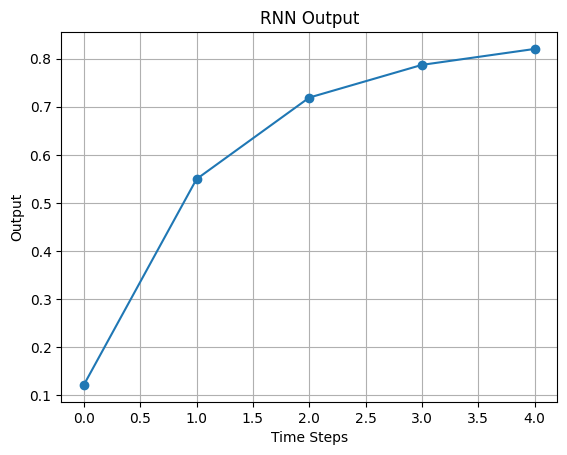

In [ ]:
# Generate final predictions
rnn.forward(input_sequence)

predictions = [
    rnn.outputs[t] for t in range(len(input_sequence))
]

values = [output[0][0] for output in predictions]

# Plot RNN Output
plt.plot(values, marker="o")

plt.title("RNN Output")
plt.xlabel("Time Steps")
plt.ylabel("Output")

plt.grid()
plt.show()
